In [3]:
from google.colab import files
uploaded = files.upload()

Saving amazon.csv to amazon.csv


In [4]:
import pandas as pd
import numpy as np
import re
import io
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (1465, 16)

Column names:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [5]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Check required columns
required = [
    "product_name", "category", "discounted_price",
    "actual_price", "discount_percentage", "rating",
    "rating_count", "about_product", "review_title",
    "review_content"
]

missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

# Convert currency, percentages and counts into numbers
def to_number(value):
    if pd.isna(value):
        return np.nan
    value = str(value).replace(",", "")
    value = re.sub(r"[₹$€£%]", "", value).strip()
    return pd.to_numeric(value, errors="coerce")

for col in ["discounted_price", "actual_price",
            "discount_percentage", "rating", "rating_count"]:
    df[col] = df[col].apply(to_number)

# Keep valid target ratings between 1 and 5
df = df[df["rating"].between(1, 5)].copy()

# Remove duplicate products when product_id is available
if "product_id" in df.columns:
    df = df.drop_duplicates(subset="product_id").copy()
else:
    df = df.drop_duplicates().copy()

# Fill missing product text
text_columns = [
    "product_name", "category", "about_product",
    "review_title", "review_content"
]

for col in text_columns:
    df[col] = df[col].fillna("").astype(str)

# Combine product details and customer reviews
df["combined_text"] = (
    df["product_name"] + " " +
    df["about_product"] + " " +
    df["review_title"] + " " +
    df["review_content"]
)

# Basic text cleaning
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["combined_text"] = df["combined_text"].apply(clean_text)

# Remove rows without usable text
df = df[df["combined_text"].str.len() > 0].copy()

print("Dataset shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df[required].isnull().sum())
print("\nRating distribution:")
print(df["rating"].value_counts().sort_index())

Missing values before cleaning:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64
Dataset shape after cleaning: (1350, 17)

Missing values after cleaning:
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
review_title           0
review_content         0
dtype: int64

Rating distribution:
rating
2.0      1
2.3      1
2.6      1
2.8      2
2.9      1
3.0      4
3.1      4
3.2      2
3.3     15
3.4     10
3.5     26
3.6     34
3.7     41
3.8     84
3.9    114
4.0    159
4.1    225
4.2

In [6]:
# Numerical product features
numeric_features = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating_count"
]

# Categorical product feature
categorical_features = ["category"]

X_text = df["combined_text"].values
X_tabular = df[numeric_features + categorical_features].copy()
y = df["rating"].astype("float32").values

# Split all inputs together to preserve row alignment
indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

X_text_train = X_text[train_idx]
X_text_test = X_text[test_idx]

X_tabular_train = X_tabular.iloc[train_idx]
X_tabular_test = X_tabular.iloc[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training records:", len(train_idx))
print("Testing records:", len(test_idx))

Training records: 1080
Testing records: 270


In [7]:
MAX_WORDS = 10000
MAX_LEN = 200

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit tokenizer only on training data
tokenizer.fit_on_texts(X_text_train)

X_seq_train = tokenizer.texts_to_sequences(X_text_train)
X_seq_test = tokenizer.texts_to_sequences(X_text_test)

X_seq_train = pad_sequences(
    X_seq_train,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_seq_test = pad_sequences(
    X_seq_test,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training sequence shape:", X_seq_train.shape)
print("Testing sequence shape:", X_seq_test.shape)

print("\nExample encoded review:")
print(X_seq_train[0][:30])

Vocabulary size: 10000
Training sequence shape: (1080, 200)
Testing sequence shape: (270, 200)

Example encoded review:
[5477 9940 9941 9942  709  694  429  545   41   47   31  890   24 2877
  567 2771  206 7537    4  842 6294 2105 1530  986    2   41  300  513
  422  755]


In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_tab_train = preprocessor.fit_transform(X_tabular_train).astype("float32")
X_tab_test = preprocessor.transform(X_tabular_test).astype("float32")

print("Training product feature shape:", X_tab_train.shape)
print("Testing product feature shape:", X_tab_test.shape)

Training product feature shape: (1080, 196)
Testing product feature shape: (270, 196)


In [9]:
# Input 1: Review text
text_input = Input(
    shape=(MAX_LEN,),
    name="text_input"
)

x = Embedding(
    input_dim=vocab_size,
    output_dim=64,
    mask_zero=True
)(text_input)

x = LSTM(64)(x)
x = Dropout(0.3)(x)

# Input 2: Product information
tabular_input = Input(
    shape=(X_tab_train.shape[1],),
    name="product_input"
)

p = Dense(32, activation="relu")(tabular_input)
p = Dropout(0.2)(p)

# Combine both inputs
combined = Concatenate()([x, p])

combined = Dense(32, activation="relu")(combined)
combined = Dropout(0.2)(combined)

# Regression output: predicted star rating
output = Dense(1, activation="linear")(combined)

model = Model(
    inputs=[text_input, tabular_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 64)   │    640,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_input       │ (None, 196)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      6,304 │ product_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      3,104 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 682,465 (2.60 MB)

 Trainable params: 682,465 (2.60 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    [X_seq_train, X_tab_train],
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - loss: 4.9349 - mae: 1.6881 - val_loss: 0.1367 - val_mae: 0.2758
Epoch 2/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - loss: 0.6995 - mae: 0.6719 - val_loss: 0.1313 - val_mae: 0.2723
Epoch 3/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step - loss: 0.6772 - mae: 0.6645 - val_loss: 0.1295 - val_mae: 0.2702
Epoch 4/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 112ms/step - loss: 0.5134 - mae: 0.5649 - val_loss: 0.1878 - val_mae: 0.3579
Epoch 5/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.4430 - mae: 0.5346 - val_loss: 0.1198 - val_mae: 0.2503
Epoch 6/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - loss: 0.5418 - mae: 0.5842 - val_loss: 0.1613 - val_mae: 0.3226
Epoch 7/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - loss: 0.4918 - mae: 0.5494 - val_loss: 0.1169 - val_mae: 0.2416
Epoch 8/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 112ms/step - loss: 0.4680 - mae: 0.5407 - val_loss: 0.1199 - val_mae: 0.2497
Epoch 9/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - lo

In [11]:
# Predict test ratings
predictions = model.predict(
    [X_seq_test, X_tab_test],
    verbose=0
).flatten()

# Keep predictions within the 1–5 star range
predictions = np.clip(predictions, 1, 5)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

within_one_star = np.mean(
    np.abs(y_test - predictions) <= 1.0
) * 100

print("MODEL EVALUATION")
print("-------------------------")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")
print(f"Within one star: {within_one_star:.2f}%")

MODEL EVALUATION
-------------------------
MAE: 0.2205
RMSE: 0.2890
R2 Score: -0.0366
Within one star: 98.89%


 Actual Rating  Predicted Rating  Absolute Error
           4.3              4.26            0.04
           4.1              4.08            0.02
           4.3              4.00            0.30
           3.9              3.94            0.04
           3.9              4.21            0.31
           3.5              4.00            0.50
           4.2              4.00            0.20
           4.4              4.17            0.23
           4.2              4.30            0.10
           4.0              4.19            0.19
           4.1              4.11            0.01
           4.2              4.03            0.17
           3.9              4.04            0.14
           4.1              3.91            0.19
           4.4              4.00            0.40
           4.3              4.27            0.03
           4.2              4.07            0.13
           4.1              4.26            0.16
           3.5              4.13            0.63
           4.1      

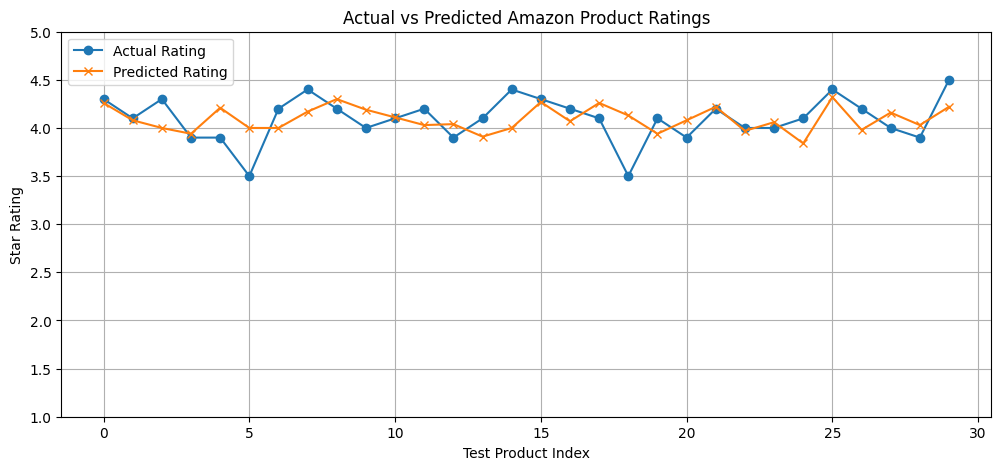

In [12]:
comparison = pd.DataFrame({
    "Actual Rating": y_test,
    "Predicted Rating": np.round(predictions, 2),
    "Absolute Error": np.round(
        np.abs(y_test - predictions), 2
    )
})

print(comparison.head(20).to_string(index=False))

# Visual comparison
n = min(30, len(comparison))

plt.figure(figsize=(12, 5))
plt.plot(
    range(n), comparison["Actual Rating"].iloc[:n],
    marker="o", label="Actual Rating"
)
plt.plot(
    range(n), comparison["Predicted Rating"].iloc[:n],
    marker="x", label="Predicted Rating"
)
plt.xlabel("Test Product Index")
plt.ylabel("Star Rating")
plt.title("Actual vs Predicted Amazon Product Ratings")
plt.ylim(1, 5)
plt.legend()
plt.grid(True)
plt.show()

In [13]:
def predict_rating(
    review,
    product_name="Unknown product",
    category="Unknown",
    about_product="",
    discounted_price=np.nan,
    actual_price=np.nan,
    discount_percentage=np.nan,
    rating_count=np.nan
):
    # Prepare the new review
    combined_text = clean_text(
        str(product_name) + " " +
        str(about_product) + " " +
        str(review)
    )

    # Convert text to a numerical sequence
    sequence = tokenizer.texts_to_sequences([combined_text])
    sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Prepare product features in the correct column order
    new_product = pd.DataFrame([{
        "discounted_price": discounted_price,
        "actual_price": actual_price,
        "discount_percentage": discount_percentage,
        "rating_count": rating_count,
        "category": category
    }])

    # Apply the already-fitted preprocessing pipeline
    product_features = preprocessor.transform(
        new_product
    ).astype("float32")

    # Predict the rating
    predicted_rating = model.predict(
        [sequence, product_features],
        verbose=0
    )[0][0]

    predicted_rating = float(
        np.clip(predicted_rating, 1, 5)
    )

    print("Product:", product_name)
    print("Customer review:", review)
    print(f"Predicted rating: {predicted_rating:.2f} / 5 stars")
    print(f"Rounded rating: {int(np.clip(np.rint(predicted_rating), 1, 5))} stars")

    return predicted_rating

In [14]:
# Example 1: Positive review
predict_rating(
    review="Excellent product, good quality and fast delivery. I love it.",
    product_name="Wireless Headphones",
    category="Electronics",
    about_product="Wireless headphones with Bluetooth connectivity",
    discounted_price=1499,
    actual_price=2499,
    discount_percentage=40,
    rating_count=500
)

print("\n" + "-" * 50 + "\n")

# Example 2: Negative review
predict_rating(
    review="Very poor quality. It stopped working after two days. Not worth buying.",
    product_name="Wireless Headphones",
    category="Electronics",
    about_product="Wireless headphones with Bluetooth connectivity",
    discounted_price=1499,
    actual_price=2499,
    discount_percentage=40,
    rating_count=500
)

Product: Wireless Headphones
Customer review: Excellent product, good quality and fast delivery. I love it.
Predicted rating: 3.80 / 5 stars
Rounded rating: 4 stars

--------------------------------------------------

Product: Wireless Headphones
Customer review: Very poor quality. It stopped working after two days. Not worth buying.
Predicted rating: 3.82 / 5 stars
Rounded rating: 4 stars


3.8240489959716797

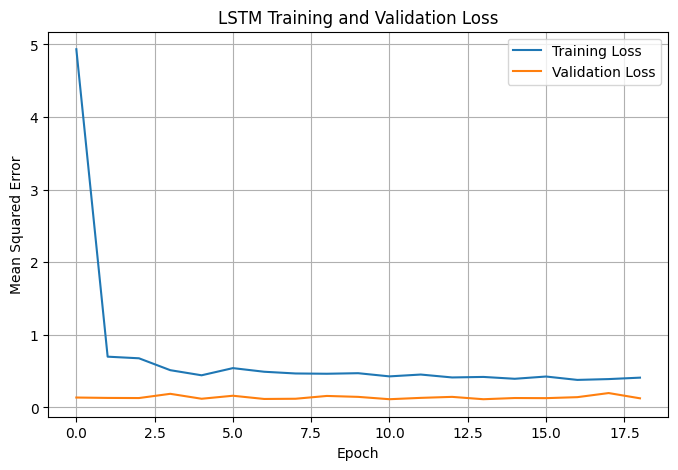

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()